# Midterm

## Fundamentos de Inteligencia Artificial

Darío Echeverría

Fuente: https://www.kaggle.com/competitions/ecuador-infant-malnutrition-competition-iisem-2026-mcd/overview

### Carga y limpieza de datos

In [1]:
# Ambiente
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Conjuntos de datos crudos
X_test_raw = pd.read_csv(r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\X_test_Kaggle.csv")
X_train_raw = pd.read_csv(r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\X_train_Kaggle.csv")
y_train_raw = pd.read_csv(r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\y_train_Kaggle.csv")
sample_submission = pd.read_csv(r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\sample_submission_malnutrition.csv")

In [3]:
X_train_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  int64  
 1   sexo                   70000 non-null  object 
 2   region                 70000 non-null  object 
 3   nivel_educacion_madre  70000 non-null  object 
 4   peso_kg                66531 non-null  float64
 5   talla_cm               62951 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 3.2+ MB


In [4]:
X_test_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             30000 non-null  int64  
 1   sexo                   30000 non-null  object 
 2   region                 30000 non-null  object 
 3   nivel_educacion_madre  30000 non-null  object 
 4   peso_kg                28517 non-null  float64
 5   talla_cm               27049 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 1.4+ MB


In [5]:
X_train_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,NaN,NaN,NaN,11.459457,8.252734,-12.0,5.0,11.0,18.0,29.0
sexo,70000,2,F,35185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,70000,4,Amazonía,17606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacion_madre,70000,4,Secundaria,31488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peso_kg,66531.0,NaN,NaN,NaN,6.879973,4.648722,-0.814205,4.500895,6.523145,8.548997,59.976104
talla_cm,62951.0,NaN,NaN,NaN,67.480033,11.937076,34.904595,57.442414,67.38153,77.444691,98.213648


**Limpieza de datos**

In [6]:
X_train_raw[X_train_raw['edad_meses']<0]

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
4,-4,F,Costa,Primaria,NaN,50.898250
5,-5,F,Sierra,Secundaria,5.562049,45.515906
7,-5,F,Costa,Superior,4.317430,45.948652
75,-1,M,Sierra,Secundaria,3.766083,50.860279
99,-10,M,Insular,Superior,9.254863,74.821153
...,...,...,...,...,...,...
69946,-5,F,Amazonía,Primaria,NaN,53.264485
69950,-5,M,Sierra,Secundaria,1.179224,48.023627
69955,-10,F,Costa,Primaria,7.606673,72.012831
69986,-2,F,Insular,Secundaria,5.380574,62.556238


In [7]:
X_train_raw[X_train_raw['edad_meses']>24]

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
27,25,M,Sierra,Sin escolaridad,10.197084,87.635580
41,29,F,Costa,Primaria,11.100097,75.448385
62,27,F,Sierra,Primaria,NaN,88.555191
63,27,F,Sierra,Superior,8.780421,83.128527
73,28,F,Amazonía,Secundaria,10.730631,84.514886
...,...,...,...,...,...,...
69876,27,M,Sierra,Superior,9.607126,83.073105
69881,25,F,Sierra,Primaria,9.866540,82.862543
69914,27,F,Costa,Superior,11.012982,82.767465
69967,27,M,Costa,Secundaria,9.858087,87.982892


In [8]:
df = X_train_raw.copy()

# Edad
# Rango válido: 0 a 24
vars_ref = ['peso_kg', 'talla_cm']

# Valores negativos a valor absoluto
mask_neg = df['edad_meses'] < 0
print(f"Registros con edad negativa: {mask_neg.sum()}")

# Medias de los registros existentes, agrupados por mes
medias_originales = df.loc[~mask_neg].groupby('edad_meses')[vars_ref].mean()

df.loc[mask_neg, 'edad_meses'] = df.loc[mask_neg, 'edad_meses'].abs()

# Medias de los registros corregidos, agrupados por su nuevo mes
medias_corregidos = df.loc[mask_neg].groupby('edad_meses')[vars_ref].mean()

comparacion_neg = medias_corregidos.join(
    medias_originales, lsuffix='_corregidos', rsuffix='_originales', how='left'
)
comparacion_neg['n_corregidos'] = df.loc[mask_neg].groupby('edad_meses').size()
comparacion_neg['dif_peso'] = comparacion_neg['peso_kg_corregidos'] - comparacion_neg['peso_kg_originales']
comparacion_neg['dif_talla'] = comparacion_neg['talla_cm_corregidos'] - comparacion_neg['talla_cm_originales']
print("\nComparación de medias por mes (negativos corregidos vs. originales):")
display(comparacion_neg.round(2))

# Valores mayores a 24 meses
mask_may24 = df['edad_meses'] > 24
mask_24_orig = df['edad_meses'] == 24
print(f"\nRegistros con edad > 24: {mask_may24.sum()}")
print(f"Registros con edad = 24 (originales): {mask_24_orig.sum()}")
print("Valores > 24 encontrados:", sorted(df.loc[mask_may24, 'edad_meses'].unique()))

df.loc[mask_may24, 'edad_meses'] = 24

comparacion_24 = pd.DataFrame({
    '24 originales': df.loc[mask_24_orig, vars_ref].mean(),
    '>24 convertidos a 24': df.loc[mask_may24, vars_ref].mean(),
})
comparacion_24['diferencia'] = comparacion_24['>24 convertidos a 24'] - comparacion_24['24 originales']
print("\nComparación de medias en el grupo de 24 meses:")
display(comparacion_24.round(2))

print(df.describe(include='all').T)


Registros con edad negativa: 3921

Comparación de medias por mes (negativos corregidos vs. originales):


,peso_kg_corregidos,talla_cm_corregidos,peso_kg_originales,talla_cm_originales,n_corregidos,dif_peso,dif_talla
edad_meses,,,,,,,
1,3.74,51.59,3.63,51.41,713,0.11,0.18
2,3.95,51.71,3.96,53.08,709,-0.01,-1.37
3,3.80,51.85,4.27,54.48,697,-0.47,-2.63
4,3.72,51.96,4.56,56.03,707,-0.84,-4.07
5,3.95,51.31,4.93,57.56,691,-0.98,-6.24
6,7.11,68.55,5.24,58.99,48,1.87,9.56
7,7.09,69.04,5.38,60.53,65,1.71,8.52
8,6.57,67.84,5.67,61.97,69,0.90,5.87
9,6.87,69.35,6.00,63.54,56,0.88,5.80



Registros con edad > 24: 3163
Registros con edad = 24 (originales): 629
Valores > 24 encontrados: [25, 26, 27, 28, 29]

Comparación de medias en el grupo de 24 meses:


,24 originales,>24 convertidos a 24,diferencia
peso_kg,10.59,10.51,-0.08
talla_cm,86.22,85.95,-0.27


                         count unique         top   freq       mean  \
edad_meses             70000.0    NaN         NaN    NaN  11.728429   
sexo                     70000      2           F  35185        NaN   
region                   70000      4    Amazonía  17606        NaN   
nivel_educacion_madre    70000      4  Secundaria  31488        NaN   
peso_kg                66531.0    NaN         NaN    NaN   6.879973   
talla_cm               62951.0    NaN         NaN    NaN  67.480033   

                             std        min        25%       50%        75%  \
edad_meses              7.411447        0.0        5.0      11.0       18.0   
sexo                         NaN        NaN        NaN       NaN        NaN   
region                       NaN        NaN        NaN       NaN        NaN   
nivel_educacion_madre        NaN        NaN        NaN       NaN        NaN   
peso_kg                 4.648722  -0.814205   4.500895  6.523145   8.548997   
talla_cm               11.93

Es importante recalcar que se está asumiendo en función a los datos que la corrección de edades a 24 meses es correcta, sin embargo conviene que se aclare esto en el metadato de la variable, para entender si en efecto son observaciones válidas a pesar de que el límite es de 2 años, o si es mejor que se eliminen para evitar sesgos hacia el grupo de 24 meses (por la inclusión de todo lo que es mayor a 24 meses en este grupo).

In [9]:
X_train_raw[(X_train_raw['peso_kg']<0) | (X_train_raw['peso_kg']>20)]

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
171,4,F,Costa,Primaria,54.269969,56.761818
745,20,F,Costa,Sin escolaridad,41.095638,88.607346
761,6,M,Costa,Sin escolaridad,35.695411,59.052059
826,5,F,Costa,Sin escolaridad,39.421744,56.268809
1033,0,M,Sierra,Primaria,36.288611,49.712551
...,...,...,...,...,...,...
69391,20,M,Insular,Secundaria,53.867996,77.837906
69442,9,M,Sierra,Secundaria,45.760378,68.634147
69451,2,M,Insular,Secundaria,52.015533,51.432298
69456,14,F,Sierra,Secundaria,31.189050,65.487504


*Acorde a la OMS, el peso de un niño o niña de hasta 2 años se encuentra en el rango de 9.7 kg y los 15.3 kg (9.7 es el valor menor del percentil 3 de niñas y 15.3 es el percentil 97 de niños), y la estatura se encuentra entre 80.7 cm a 93.5 cm (80.7 es el valor menor del percentil 3 de niñas y 93.5 es el percentil 97 de niños).*

In [10]:
# Imputación de peso_kg y talla_cm con la media del grupo (edad_meses, sexo)
vars_imp = ['peso_kg', 'talla_cm']
grupos = ['edad_meses', 'sexo']

# Pesos negativos o cero a NaN (valores imposibles)
mask_peso_inv = df['peso_kg'] <= 0
print(f"Pesos negativos o cero convertidos a NaN: {mask_peso_inv.sum()}")
df.loc[mask_peso_inv, 'peso_kg'] = np.nan

stats_antes = df[vars_imp].agg(['mean', 'std', 'min', 'max'])

# Atípicos por IQR dentro de cada grupo a NaN
for var in vars_imp:
    q1 = df.groupby(grupos)[var].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby(grupos)[var].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    mask_atip = (df[var] < lim_inf) | (df[var] > lim_sup)
    print(f"Atípicos en {var}: {mask_atip.sum()} "
          f"(bajos: {(df[var] < lim_inf).sum()}, altos: {(df[var] > lim_sup).sum()})")
    df.loc[mask_atip, var] = np.nan

print("\nNaN antes de imputar:")
print(df[vars_imp].isna().sum())

# Media de cada grupo (calculada sin inválidos ni atípicos), alineada a cada registro
medias_grupo = df.groupby(grupos)[vars_imp].transform('mean')
df[vars_imp] = df[vars_imp].fillna(medias_grupo)

print("\nNaN después de imputar:")
print(df[vars_imp].isna().sum())

stats_despues = df[vars_imp].agg(['mean', 'std', 'min', 'max'])
print("\nEstadísticos antes vs. después:")
display(pd.concat({'antes': stats_antes, 'después': stats_despues}).round(3))

# Medias usadas por grupo (para revisión)
display(df.groupby(grupos)[vars_imp].mean().unstack('sexo').round(2))


Pesos negativos o cero convertidos a NaN: 11
Atípicos en peso_kg: 1320 (bajos: 246, altos: 1074)
Atípicos en talla_cm: 760 (bajos: 282, altos: 478)

NaN antes de imputar:
peso_kg     4800
talla_cm    7809
dtype: int64

NaN después de imputar:
peso_kg     0
talla_cm    0
dtype: int64

Estadísticos antes vs. después:


peso_kg  talla_cm
antes   mean    6.881    67.480
        std     4.648    11.937
        min     0.019    34.905
        max    59.976    98.214
después mean    6.479    67.415
        std     2.468    11.823
        min     0.408    40.918
        max    12.956    95.828

peso_kg        talla_cm       
sexo             F      M        F      M
edad_meses                               
0             2.94   3.01    49.87  49.90
1             3.22   3.26    51.25  51.08
2             3.49   3.48    52.61  52.46
3             3.73   3.75    53.76  53.70
4             3.94   3.99    54.87  55.01
5             4.21   4.18    56.14  56.21
6             4.85   4.86    58.98  59.02
7             5.10   5.06    60.57  60.46
8             5.36   5.44    62.01  61.91
9             5.72   5.69    63.61  63.51
10            6.01   5.99    65.04  65.04
11            6.33   6.29    66.50  66.57
12            6.57   6.59    68.02  67.94
13            6.85   6.88    69.48  69.41
14            7.20   7.20    71.08  71.02
15            7.51   7.52    72.56  72.62
16            7.84   7.75    74.05  74.18
17            8.13   8.05    75.38  75.50
18            8.43   8.39    77.12  77.16
19            8.68   8.70    78.38  78.45
20            9.05   9.01    79.79  80.07
21            9.33   9.28    81.36  81.44
22            9.61   9.64    83.07  83.20
23            9.90   9.92    84.65  84.57
24           10.19  10.23    85.93  86.05

In [11]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,NaN,NaN,NaN,11.728429,7.411447,0.0,5.0,11.0,18.0,24.0
sexo,70000,2,F,35185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,70000,4,Amazonía,17606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacion_madre,70000,4,Secundaria,31488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peso_kg,70000.0,NaN,NaN,NaN,6.479491,2.468084,0.4076,4.458023,6.457551,8.465129,12.955962
talla_cm,70000.0,NaN,NaN,NaN,67.414714,11.823205,40.917704,57.315198,67.248731,77.316602,95.827535


In [12]:
X_train = df.copy()

### EDA

In [13]:
datos = X_train.assign(alerta_desnutricion=y_train_raw['alerta_desnutricion'])
datos.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,NaN,NaN,NaN,11.728429,7.411447,0.0,5.0,11.0,18.0,24.0
sexo,70000,2,F,35185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,70000,4,Amazonía,17606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacion_madre,70000,4,Secundaria,31488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peso_kg,70000.0,NaN,NaN,NaN,6.479491,2.468084,0.4076,4.458023,6.457551,8.465129,12.955962
talla_cm,70000.0,NaN,NaN,NaN,67.414714,11.823205,40.917704,57.315198,67.248731,77.316602,95.827535
alerta_desnutricion,70000.0,NaN,NaN,NaN,0.100129,0.300173,0.0,0.0,0.0,0.0,1.0


In [14]:
num_cols = ['edad_meses', 'peso_kg', 'talla_cm']

sns.catplot(
    data=datos.melt(id_vars='alerta_desnutricion', value_vars=num_cols),
    x='alerta_desnutricion', y='value', col='variable',
    kind='box', sharey=False, height=4, aspect=0.8
)

<Axes: title={'center': 'variable = talla_cm'}, xlabel='alerta_desnutricion', ylabel='talla_cm'>

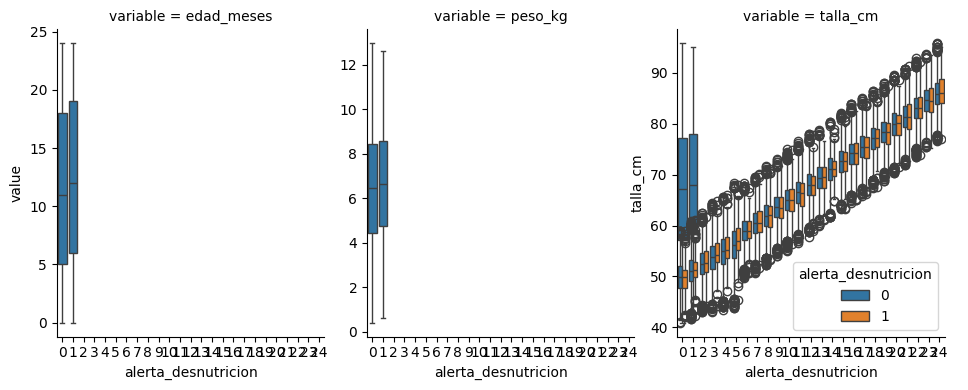

In [15]:
sns.boxplot(data=datos, x='edad_meses', y='talla_cm', hue='alerta_desnutricion')

<Axes: xlabel='edad_meses', ylabel='peso_kg'>

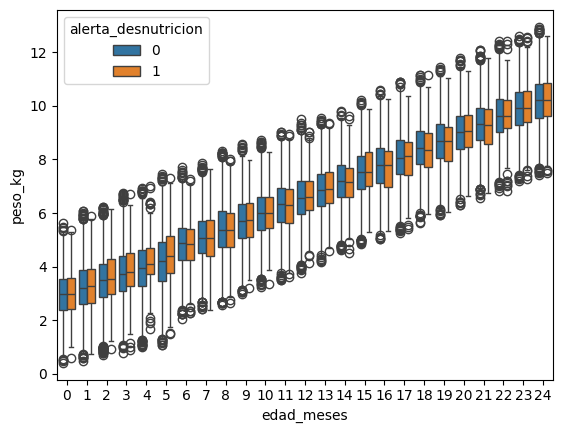

In [16]:
sns.boxplot(data=datos, x='edad_meses', y='peso_kg', hue='alerta_desnutricion')


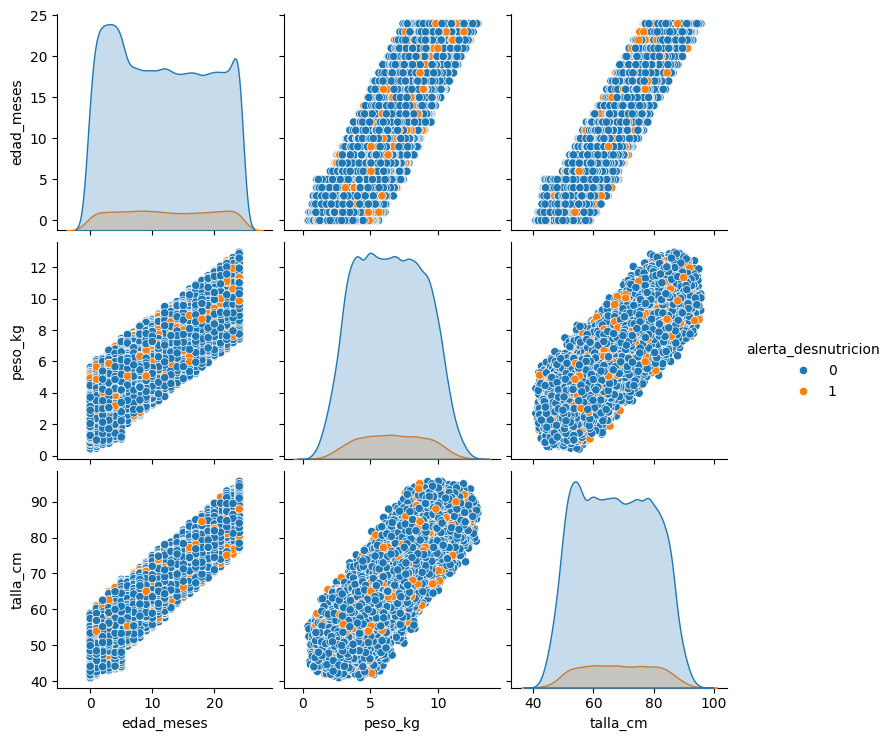

In [17]:
sns.pairplot(datos, hue='alerta_desnutricion')

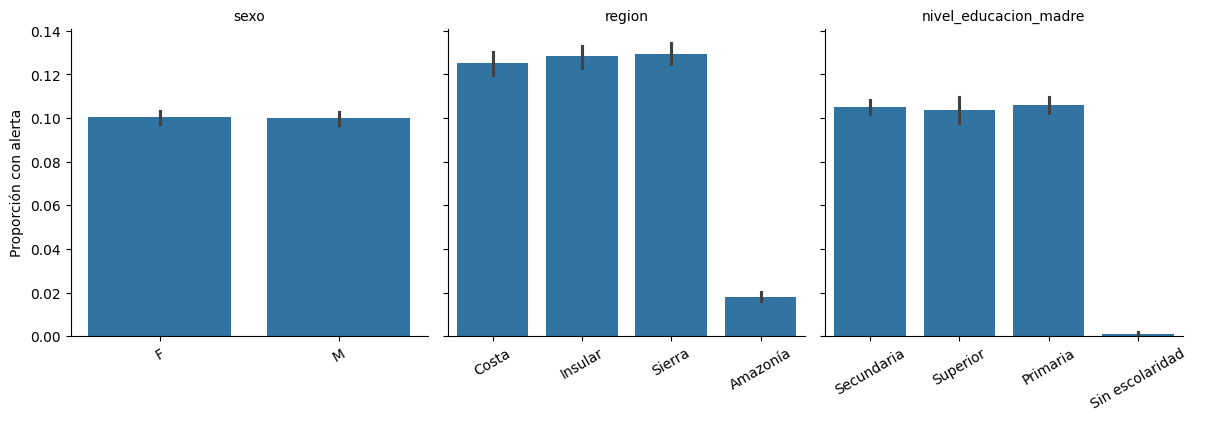

In [18]:
cat_cols = ['sexo', 'region', 'nivel_educacion_madre']

g = sns.catplot(
    data=datos.melt(id_vars='alerta_desnutricion', value_vars=cat_cols),
    x='value', y='alerta_desnutricion', col='variable',
    kind='bar', sharex=False, height=4, aspect=1
)
g.set_axis_labels('', 'Proporción con alerta')
g.set_titles('{col_name}')
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=30)

<Axes: xlabel='region', ylabel='count'>

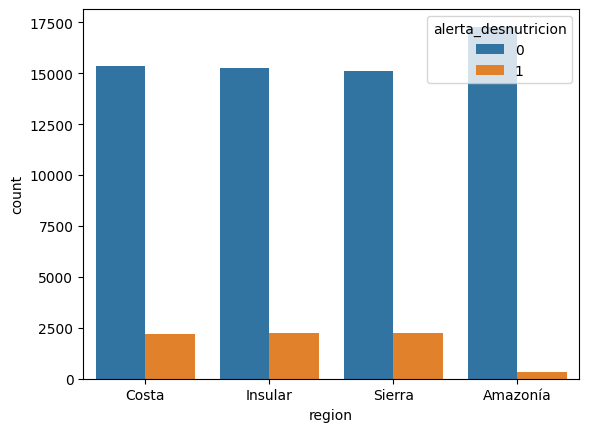

In [19]:
sns.countplot(data=datos, x='region', hue='alerta_desnutricion')

In [20]:
for col in cat_cols:
    display(pd.crosstab(datos[col], datos['alerta_desnutricion'],
                        normalize='index', margins=True).round(3))


alerta_desnutricion,0,1
sexo,,
F,0.9,0.1
M,0.9,0.1
All,0.9,0.1


alerta_desnutricion,0,1
region,,
Amazonía,0.982,0.018
Costa,0.875,0.125
Insular,0.872,0.128
Sierra,0.870,0.130
All,0.900,0.100


alerta_desnutricion,0,1
nivel_educacion_madre,,
Primaria,0.894,0.106
Secundaria,0.895,0.105
Sin escolaridad,0.999,0.001
Superior,0.896,0.104
All,0.900,0.100


Los datos graficados con los diagramas de cajas muestran la clara tendencia de los valores a incrementar, conforme avanzan los meses, para ambos grupos de la variable objetivo. Para las categorías de Amazonía con desnutrición, y de Sin escolaridad sin desnutrición, es posible que el modelo no cubra de manera clara una predicción debido a la cantidad baja de observaciones.

### Modelado

In [21]:
# Codificación de variables categóricas
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['sexo', 'region', 'nivel_educacion_madre']

ohe = OneHotEncoder(
    drop='if_binary',          # sexo queda en una sola columna 0/1
    handle_unknown='ignore',   # si test trae una categoría nueva, se codifica como todo ceros
    sparse_output=False
).set_output(transform='pandas')

X_cat = ohe.fit_transform(df[cat_cols])
X_train = pd.concat([df.drop(columns=cat_cols), X_cat], axis=1)

print(X_train.columns.tolist())
assert X_train.index.equals(X_train_raw.index)


['edad_meses', 'peso_kg', 'talla_cm', 'sexo_M', 'region_Amazonía', 'region_Costa', 'region_Insular', 'region_Sierra', 'nivel_educacion_madre_Primaria', 'nivel_educacion_madre_Secundaria', 'nivel_educacion_madre_Sin escolaridad', 'nivel_educacion_madre_Superior']


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

y = y_train_raw['alerta_desnutricion']
grupos = ['edad_meses', 'sexo']

# Referencia de crecimiento por (edad, sexo), calculada solo con train
ref = df.groupby(grupos)[['peso_kg', 'talla_cm']].agg(['mean', 'std'])

def variables_derivadas(data, ref):
    stats = ref.reindex(pd.MultiIndex.from_frame(data[grupos]))
    out = pd.DataFrame(index=data.index)
    for var in ['peso_kg', 'talla_cm']:
        out[f'z_{var}'] = (data[var].values - stats[(var, 'mean')].values) / stats[(var, 'std')].values
    out['imc'] = data['peso_kg'] / (data['talla_cm'] / 100) ** 2
    return out

X_train_fe = X_train.join(variables_derivadas(df, ref))

# Modelos seleccionados: Regresión Logística (como referencia base) y Gradient Boosting
# Balanceados
modelos = {
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'HistGB': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
}

# Validación cruzada estratificada (5 folds) para F1 y Accuracy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nombre_X, X in {'originales': X_train, 'con z-scores': X_train_fe}.items():
    for nombre_m, modelo in modelos.items():
        f1 = cross_val_score(modelo, X, y, cv=cv, scoring='f1')
        print(f"{nombre_m:7s} | {nombre_X:13s} | F1 = {f1.mean():.3f} ± {f1.std():.3f}")
        
for nombre_X, X in {'originales': X_train, 'con z-scores': X_train_fe}.items():
    for nombre_m, modelo in modelos.items():
        acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
        print(f"{nombre_m:7s} | {nombre_X:13s} | Accuracy = {acc.mean():.3f} ± {acc.std():.3f}")


LogReg  | originales    | F1 = 0.236 ± 0.001
HistGB  | originales    | F1 = 0.239 ± 0.001
LogReg  | con z-scores  | F1 = 0.239 ± 0.002
HistGB  | con z-scores  | F1 = 0.238 ± 0.002
LogReg  | originales    | Accuracy = 0.380 ± 0.003
HistGB  | originales    | Accuracy = 0.430 ± 0.006
LogReg  | con z-scores  | Accuracy = 0.407 ± 0.003
HistGB  | con z-scores  | Accuracy = 0.431 ± 0.004


In [23]:
# Modelos seleccionados: Regresión Logística (como referencia base) y Gradient Boosting
# Sin balancear
modelos = {
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'HistGB': HistGradientBoostingClassifier(random_state=42),
}

# Validación cruzada estratificada (5 folds) para F1 y Accuracy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nombre_X, X in {'originales': X_train, 'con z-scores': X_train_fe}.items():
    for nombre_m, modelo in modelos.items():
        f1 = cross_val_score(modelo, X, y, cv=cv, scoring='f1')
        print(f"{nombre_m:7s} | {nombre_X:13s} | F1 = {f1.mean():.3f} ± {f1.std():.3f}")
        
for nombre_X, X in {'originales': X_train, 'con z-scores': X_train_fe}.items():
    for nombre_m, modelo in modelos.items():
        acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
        print(f"{nombre_m:7s} | {nombre_X:13s} | Accuracy = {acc.mean():.3f} ± {acc.std():.3f}")


LogReg  | originales    | F1 = 0.000 ± 0.000
HistGB  | originales    | F1 = 0.000 ± 0.000
LogReg  | con z-scores  | F1 = 0.000 ± 0.000
HistGB  | con z-scores  | F1 = 0.000 ± 0.000
LogReg  | originales    | Accuracy = 0.900 ± 0.000
HistGB  | originales    | Accuracy = 0.900 ± 0.000
LogReg  | con z-scores  | Accuracy = 0.900 ± 0.000
HistGB  | con z-scores  | Accuracy = 0.900 ± 0.000


In [24]:
# Verificación de modelos utilizables para clasificación con PyCaret
from pycaret.classification import setup, compare_models, pull

data_pc = X_train.assign(alerta_desnutricion=y_train_raw['alerta_desnutricion'])

exp = setup(
    data=data_pc,
    target='alerta_desnutricion',
    train_size=0.8,                    # 20% se reserva como prueba
    fold=5,
    fold_strategy='stratifiedkfold',   # cada fold conserva el 10% de positivos
    normalize=True,                    # escala para LogReg, KNN y SVM (a los árboles no les afecta)
    session_id=42,                     # semilla para resultados reproducibles
    verbose=False,
)

top3 = compare_models(sort='AUC', n_select=3)
resultados = pull()
display(resultados)


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8997,0.6504,0.0004,0.2000,0.0007,0.0002,0.0037,1.3020
nb,Naive Bayes,0.3789,0.6487,0.9543,0.1342,0.2353,0.0725,0.1785,0.6480
lr,Logistic Regression,0.8999,0.6486,0.0000,0.0000,0.0000,0.0000,0.0000,0.8200
ada,Ada Boost Classifier,0.8999,0.6476,0.0000,0.0000,0.0000,0.0000,0.0000,0.3720
ridge,Ridge Classifier,0.8999,0.6473,0.0000,0.0000,0.0000,0.0000,0.0000,0.0520
lda,Linear Discriminant Analysis,0.8999,0.6473,0.0000,0.0000,0.0000,0.0000,0.0000,0.0480
rf,Random Forest Classifier,0.8897,0.6141,0.0214,0.1482,0.0374,0.0124,0.0194,0.9140
et,Extra Trees Classifier,0.8776,0.6056,0.0432,0.1402,0.0659,0.0196,0.0237,0.6380
svm,SVM - Linear Kernel,0.8999,0.6035,0.0000,0.0000,0.0000,0.0000,0.0000,0.0580
knn,K Neighbors Classifier,0.8900,0.5628,0.0200,0.1442,0.0351,0.0109,0.0173,1.5640


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8997,0.6504,0.0004,0.2000,0.0007,0.0002,0.0037,1.302
nb,Naive Bayes,0.3789,0.6487,0.9543,0.1342,0.2353,0.0725,0.1785,0.648
lr,Logistic Regression,0.8999,0.6486,0.0000,0.0000,0.0000,0.0000,0.0000,0.820
ada,Ada Boost Classifier,0.8999,0.6476,0.0000,0.0000,0.0000,0.0000,0.0000,0.372
ridge,Ridge Classifier,0.8999,0.6473,0.0000,0.0000,0.0000,0.0000,0.0000,0.052
lda,Linear Discriminant Analysis,0.8999,0.6473,0.0000,0.0000,0.0000,0.0000,0.0000,0.048
rf,Random Forest Classifier,0.8897,0.6141,0.0214,0.1482,0.0374,0.0124,0.0194,0.914
et,Extra Trees Classifier,0.8776,0.6056,0.0432,0.1402,0.0659,0.0196,0.0237,0.638
svm,SVM - Linear Kernel,0.8999,0.6035,0.0000,0.0000,0.0000,0.0000,0.0000,0.058
knn,K Neighbors Classifier,0.8900,0.5628,0.0200,0.1442,0.0351,0.0109,0.0173,1.564


### Resultados

In [25]:
# Limpieza reproducible: parámetros aprendidos en train, aplicados a train y test
grupos = ['edad_meses', 'sexo']
vars_imp = ['peso_kg', 'talla_cm']

def por_grupo(data, tabla):
    """Alinea una tabla indexada por (edad_meses, sexo) con cada fila de data."""
    return tabla.reindex(pd.MultiIndex.from_frame(data[grupos])).set_axis(data.index)

def corregir_valores(data):
    """Reglas fijas: edad negativa a positiva, edad > 24 a 24, peso <= 0 a NaN."""
    out = data.copy()
    out['edad_meses'] = out['edad_meses'].abs().clip(upper=24)
    out.loc[out['peso_kg'] <= 0, 'peso_kg'] = np.nan
    return out

def quitar_atipicos(data, params):
    """Valores fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR] de su grupo a NaN."""
    out = data.copy()
    lim_inf = por_grupo(out, params['lim_inf'])
    lim_sup = por_grupo(out, params['lim_sup'])
    for var in vars_imp:
        mask = (out[var] < lim_inf[var]) | (out[var] > lim_sup[var])
        out.loc[mask, var] = np.nan
    return out

def ajustar_limpieza(train_raw):
    """Aprende de train los límites IQR y las medias por grupo."""
    base = corregir_valores(train_raw)
    q1 = base.groupby(grupos)[vars_imp].quantile(0.25)
    q3 = base.groupby(grupos)[vars_imp].quantile(0.75)
    iqr = q3 - q1
    params = {'lim_inf': q1 - 1.5 * iqr, 'lim_sup': q3 + 1.5 * iqr}
    sin_atipicos = quitar_atipicos(base, params)
    params['medias'] = sin_atipicos.groupby(grupos)[vars_imp].mean()
    params['medias_globales'] = sin_atipicos[vars_imp].mean()  # respaldo si un grupo no existe en train
    return params

def limpiar(data, params):
    """Aplica toda la limpieza con parámetros ya aprendidos."""
    out = quitar_atipicos(corregir_valores(data), params)
    out[vars_imp] = (out[vars_imp]
                     .fillna(por_grupo(out, params['medias']))
                     .fillna(params['medias_globales']))
    return out

# 1. Aprender parámetros de train y comprobar que se reproduce la limpieza original
params = ajustar_limpieza(X_train_raw)
pd.testing.assert_frame_equal(limpiar(X_train_raw, params), df)
print("La limpieza reproduce exactamente el df de train")

# 2. Diagnóstico de test antes de limpiar
print(f"\nTest: edad < 0: {(X_test_raw['edad_meses'] < 0).sum()} | "
      f"edad > 24: {(X_test_raw['edad_meses'] > 24).sum()} | "
      f"peso <= 0: {(X_test_raw['peso_kg'] <= 0).sum()}")
print("NaN originales en test:")
print(X_test_raw[vars_imp].isna().sum())

# 3. Limpiar test, codificar y agregar variables derivadas (todo con objetos de train)
df_test = limpiar(X_test_raw, params)
X_test = pd.concat([df_test.drop(columns=cat_cols), ohe.transform(df_test[cat_cols])], axis=1)
X_test_fe = X_test.join(variables_derivadas(df_test, ref))

# 4. Verificaciones
assert len(X_test) == len(X_test_raw), "Se perdieron registros"
assert X_test.index.equals(X_test_raw.index), "El índice cambió"
assert list(X_test.columns) == list(X_train.columns), "Las columnas no coinciden con train"
assert X_test.isna().sum().sum() == 0, "Quedaron NaN"
print(f"\nX_test: {X_test.shape} | edad: {X_test['edad_meses'].min()} a {X_test['edad_meses'].max()}")
display(df_test[vars_imp].describe().T.round(2))

La limpieza reproduce exactamente el df de train

Test: edad < 0: 1665 | edad > 24: 1333 | peso <= 0: 4
NaN originales en test:
peso_kg     1483
talla_cm    2951
dtype: int64

X_test: (30000, 12) | edad: 0 a 24


,count,mean,std,min,25%,50%,75%,max
peso_kg,30000.0,6.48,2.47,0.45,4.45,6.47,8.47,12.75
talla_cm,30000.0,67.39,11.80,40.64,57.20,67.43,77.17,94.94


In [26]:
# Entrega preliminar: HistGradientBoosting con sklearn
modelo = HistGradientBoostingClassifier(random_state=42)  # sin class_weight: la métrica es accuracy

# Accuracy esperada (validación cruzada) vs. línea base de predecir todo 0
acc = cross_val_score(modelo, X_train, y, cv=cv, scoring='accuracy')
print(f"Accuracy CV: {acc.mean():.4f} ± {acc.std():.4f} | línea base (todo 0): {1 - y.mean():.4f}")

# Entrenar con el 100% de train y predecir test
modelo.fit(X_train, y)
pred_test = modelo.predict(X_test)
print("\nPredicciones en test:")
print(pd.Series(pred_test).value_counts())

# Archivo de entrega (mismo orden de filas que X_test_raw)
submission = sample_submission.copy()
submission['alerta_desnutricion'] = pred_test
assert len(submission) == len(X_test_raw)
submission.to_csv(
    r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\submission_preliminar.csv",
    index=False
)
display(submission.head())

Accuracy CV: 0.8999 ± 0.0000 | línea base (todo 0): 0.8999

Predicciones en test:
0    30000
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [27]:
# Entrega con clases balanceadas: HistGradientBoosting + class_weight='balanced'
modelo_bal = HistGradientBoostingClassifier(class_weight='balanced', random_state=42)

# Accuracy esperada (validación cruzada) vs. línea base de predecir todo 0
acc_bal = cross_val_score(modelo_bal, X_train, y, cv=cv, scoring='accuracy')
print(f"Accuracy CV: {acc_bal.mean():.4f} ± {acc_bal.std():.4f} | línea base (todo 0): {1 - y.mean():.4f}")

# Entrenar con el 100% de train y predecir test
modelo_bal.fit(X_train, y)
pred_test_bal = modelo_bal.predict(X_test)
print("\nPredicciones en test:")
print(pd.Series(pred_test_bal).value_counts())

# Archivo de entrega (mismo orden de filas que X_test_raw)
submission_bal = sample_submission.copy()
submission_bal['alerta_desnutricion'] = pred_test_bal
assert len(submission_bal) == len(X_test_raw)
submission_bal.to_csv(
    r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\submission_balanceado.csv",
    index=False
)
display(submission_bal.head())

# Comparación entre ambas entregas
print("\nComparación de entregas:")
display(pd.DataFrame({
    'Accuracy CV': [acc.mean(), acc_bal.mean()],
    'Alertas predichas en test': [pred_test.sum(), pred_test_bal.sum()],
    '% de alertas en test': [pred_test.mean(), pred_test_bal.mean()],
}, index=['sin balancear', 'balanceado']).round(4))


Accuracy CV: 0.4305 ± 0.0061 | línea base (todo 0): 0.8999

Predicciones en test:
1    19937
0    10063
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,1
1,2,0
2,3,0
3,4,1
4,5,1



Comparación de entregas:


,Accuracy CV,Alertas predichas en test,% de alertas en test
sin balancear,0.8999,0,0.0000
balanceado,0.4305,19937,0.6646


In [28]:
# Entrega con clases balanceadas: Regresión Logística + class_weight='balanced'
modelo_lr_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000)
)

# Accuracy esperada (validación cruzada) vs. línea base de predecir todo 0
acc_lr_bal = cross_val_score(modelo_lr_bal, X_train, y, cv=cv, scoring='accuracy')
print(f"LogReg balanceado | Accuracy CV: {acc_lr_bal.mean():.4f} ± {acc_lr_bal.std():.4f} | línea base (todo 0): {1 - y.mean():.4f}")

# Entrenar con el 100% de train y predecir test
modelo_lr_bal.fit(X_train, y)
pred_test_lr_bal = modelo_lr_bal.predict(X_test)
print("\nLogReg balanceado | Predicciones en test:")
print(pd.Series(pred_test_lr_bal).value_counts())

# Archivo de entrega (mismo orden de filas que X_test_raw)
submission_lr_bal = sample_submission.copy()
submission_lr_bal['alerta_desnutricion'] = pred_test_lr_bal
assert len(submission_lr_bal) == len(X_test_raw)
submission_lr_bal.to_csv(
    r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\submission_logreg_balanceado.csv",
    index=False
)
display(submission_lr_bal.head())

# Entrega sin balancear: Regresión Logística
modelo_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight=None, max_iter=1000)  # sin balancear: la métrica es accuracy
)

# Accuracy esperada (validación cruzada) vs. línea base de predecir todo 0
acc_lr = cross_val_score(modelo_lr, X_train, y, cv=cv, scoring='accuracy')
print(f"\nLogReg sin balancear | Accuracy CV: {acc_lr.mean():.4f} ± {acc_lr.std():.4f} | línea base (todo 0): {1 - y.mean():.4f}")

# Entrenar con el 100% de train y predecir test
modelo_lr.fit(X_train, y)
pred_test_lr = modelo_lr.predict(X_test)
print("\nLogReg sin balancear | Predicciones en test:")
print(pd.Series(pred_test_lr).value_counts())

# Archivo de entrega (mismo orden de filas que X_test_raw)
submission_lr = sample_submission.copy()
submission_lr['alerta_desnutricion'] = pred_test_lr
assert len(submission_lr) == len(X_test_raw)
submission_lr.to_csv(
    r"D:\MCD_UITEY\3_fundamentos_de_inteligencia_artificial\midterm\submission_logreg.csv",
    index=False
)
display(submission_lr.head())

# Comparación entre ambas entregas
print("\nComparación de entregas:")
display(pd.DataFrame({
    'Accuracy CV': [acc_lr_bal.mean(), acc_lr.mean()],
    'Alertas predichas en test': [pred_test_lr_bal.sum(), pred_test_lr.sum()],
    '% de alertas en test': [pred_test_lr_bal.mean(), pred_test_lr.mean()],
}, index=['LogReg balanceado', 'LogReg sin balancear']).round(4))


LogReg balanceado | Accuracy CV: 0.3804 ± 0.0029 | línea base (todo 0): 0.8999

LogReg balanceado | Predicciones en test:
1    21448
0     8552
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,1
1,2,0
2,3,0
3,4,1
4,5,1



LogReg sin balancear | Accuracy CV: 0.8999 ± 0.0000 | línea base (todo 0): 0.8999

LogReg sin balancear | Predicciones en test:
0    30000
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0



Comparación de entregas:


,Accuracy CV,Alertas predichas en test,% de alertas en test
LogReg balanceado,0.3804,21448,0.7149
LogReg sin balancear,0.8999,0,0.0000


In [35]:
from sklearn.model_selection import cross_validate

# Ablación: AUC del modelo al quitar cada variable (o grupo de dummies)
grupos_vars = {
    'edad_meses': ['edad_meses'],
    'peso_kg': ['peso_kg'],
    'talla_cm': ['talla_cm'],
    'sexo': ['sexo_M'],
    'region': [c for c in X_train.columns if c.startswith('region_')],
    'nivel_educacion_madre': [c for c in X_train.columns if c.startswith('nivel_educacion_madre_')],
}

hgb = HistGradientBoostingClassifier(random_state=42)
metricas = ['roc_auc', 'accuracy']

r = cross_validate(hgb, X_train, y, cv=cv, scoring=metricas)
auc_cv_gb, acc_cv_gb = r['test_roc_auc'], r['test_accuracy']
print(f"AUC con todas las variables: {auc_cv_gb.mean():.4f} ± {auc_cv_gb.std():.4f}")
print(f"Accuracy con todas las variables: {acc_cv_gb.mean():.4f} ± {acc_cv_gb.std():.4f}")

filas = []
for nombre, cols in grupos_vars.items():
    r = cross_validate(hgb, X_train.drop(columns=cols), y, cv=cv, scoring=metricas)
    auc_sin, acc_sin = r['test_roc_auc'].mean(), r['test_accuracy'].mean()
    filas.append({'variable eliminada': nombre,
                  'AUC sin la variable': auc_sin,
                  'cambio AUC': auc_sin - auc_cv_gb.mean(),
                  'Accuracy sin la variable': acc_sin,
                  'cambio Accuracy': acc_sin - acc_cv_gb.mean()})

ablacion_gb = pd.DataFrame(filas).sort_values('cambio AUC')
display(ablacion_gb.round(4))

AUC con todas las variables: 0.6490 ± 0.0049
Accuracy con todas las variables: 0.8999 ± 0.0000


,variable eliminada,AUC sin la variable,cambio AUC,Accuracy sin la variable,cambio Accuracy
4,region,0.5412,-0.1078,0.8999,0.0
5,nivel_educacion_madre,0.6271,-0.0219,0.8999,0.0
0,edad_meses,0.6467,-0.0023,0.8999,0.0
3,sexo,0.6490,0.0000,0.8999,0.0
2,talla_cm,0.6491,0.0001,0.8999,0.0
1,peso_kg,0.6509,0.0019,0.8999,0.0


In [32]:
# Ablación: AUC del modelo al quitar cada variable (o grupo de dummies)
grupos_vars = {
    'edad_meses': ['edad_meses'],
    'peso_kg': ['peso_kg'],
    'talla_cm': ['talla_cm'],
    'sexo': ['sexo_M'],
    'region': [c for c in X_train.columns if c.startswith('region_')],
    'nivel_educacion_madre': [c for c in X_train.columns if c.startswith('nivel_educacion_madre_')],
}

logreg = LogisticRegression(class_weight=None, max_iter=1000)
auc_cv_lr = cross_val_score(logreg, X_train, y, cv=cv, scoring='roc_auc')
print(f"AUC con todas las variables: {auc_cv_lr.mean():.4f} ± {auc_cv_lr.std():.4f}")

filas = []
for nombre, cols in grupos_vars.items():
    auc_sin = cross_val_score(logreg, X_train.drop(columns=cols), y, cv=cv, scoring='roc_auc').mean()
    filas.append({'variable eliminada': nombre,
                  'AUC sin la variable': auc_sin,
                  'cambio': auc_sin - auc_cv_lr.mean()})

ablacion = pd.DataFrame(filas).sort_values('cambio')
display(ablacion.round(4))

AUC con todas las variables: 0.6490 ± 0.0057


,variable eliminada,AUC sin la variable,cambio
4,region,0.5457,-0.1032
5,nivel_educacion_madre,0.6288,-0.0201
2,talla_cm,0.6475,-0.0015
1,peso_kg,0.6489,-0.0001
0,edad_meses,0.6489,-0.0000
3,sexo,0.6489,-0.0000


Con el uso del modelo Gradient Boosting, balanceando las clases, se obtuvo una calificación baja dentro de la entrega.

Con un análisis adicional, utilizando pycaret, se obtuvo que la métrica de Precisión es prácticamente indistinta con respecto a los modelos utilizados (Regresión Logística y Gradient Boosting), por lo que, para la segunda entrega, se utilizó la regresión logística sin balanceo de clases.

De igual manera, se realizó un análisis de ablación para las variables de predicción bajo la métrica de AUC (esto considerando que la precisión es casi igual entre los modelos), lo que arrojó que, para el modelo Gradient Boosting el peso en kg puede retirarse de las variables predictoras y obtener una leve mejora, sin embargo no es representativa; en cambio la regresión logística no tuvo ninguna mejora en esta métrica.

Es posible que la cantidad de positivos para desnutrición no sean suficientes para desarrollar un modelo con métricas aceptables que no solamente prediga los casos que no son desnutrición (con etiquetas 0).